# Top 20% decline prediction: encoding

Load `h4_shrink_feature_table_raw.csv` (the output of the feature-engineering notebook) and convert it into a numeric matrix that can go into the model.

**Policy (settled)**
- Missing demographics (180 households) appear in all 6 columns at once, so mark them with a single binary variable, `has_demo` (record present or not),
  and for the remaining ordinal and nominal columns replace them with the mode before encoding (to avoid double marking)
- Ordinal (AGE_DESC, INCOME_DESC, HOUSEHOLD_SIZE_DESC, KID_CATEGORY_DESC): integer encoding that preserves the order
- Nominal (HOMEOWNER_DESC, HH_COMP_DESC): one-hot encoding, with the **mode** as the reference category
  (the "Unknown" of HH_COMP_DESC can stand in for atypical households such as large families, so it is kept as its own category and not used as the reference)

In [1]:
import pandas as pd
import numpy as np
from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 150)

feature_table = pd.read_csv(INTERMEDIATE_DIR / "h4_shrink_feature_table_raw.csv", index_col=0).sort_index()
feature_table.index.name = "HOUSEHOLD_KEY"
print(f"Original shape: {feature_table.shape}")
feature_table.head()


Original shape: (499, 12)


,sales_early,n_baskets,avg_items_per_basket,category_diversity,exposure_ratio,AGE_DESC,INCOME_DESC,HOMEOWNER_DESC,HH_COMP_DESC,HOUSEHOLD_SIZE_DESC,KID_CATEGORY_DESC,label_shrink
HOUSEHOLD_KEY,,,,,,,,,,,,
6,880.36,30,9.500000,80,0.203509,Not reported,Not reported,Not reported,Not reported,Not reported,Not reported,1
13,1899.43,36,9.083333,89,0.293578,25-34,75-99K,Homeowner,2 Adults Kids,4,2,0
17,554.76,15,6.133333,43,0.173913,65+,Under 15K,Homeowner,2 Adults No Kids,2,None/Unknown,1
18,678.38,15,13.333333,73,0.220000,45-54,100-124K,Homeowner,2 Adults No Kids,2,None/Unknown,0
19,762.90,25,12.880000,89,0.400621,35-44,15-24K,Unknown,Single Female,1,None/Unknown,0


## 1. Separate whether a demographic record exists (has_demo)

The 180 households have all 6 demographic columns filled at once with "Not reported", so extract that fact itself as a single binary variable.

In [2]:
demo_cols = ["AGE_DESC", "INCOME_DESC", "HOMEOWNER_DESC", "HH_COMP_DESC",
             "HOUSEHOLD_SIZE_DESC", "KID_CATEGORY_DESC"]

# Check whether the rows with "Not reported" in all 6 columns are all the same 180 households
missing_mask = (feature_table[demo_cols] == "Not reported").all(axis=1)
print(f"Households with 'Not reported' in all 6 columns: {missing_mask.sum()}")
print(f"Households with 'Not reported' in only some columns (should be none): {((feature_table[demo_cols] == 'Not reported').any(axis=1) & ~missing_mask).sum()}")

feature_table["has_demo"] = (~missing_mask).astype(int)
print("\nhas_demo distribution")
print(feature_table["has_demo"].value_counts())


Households with 'Not reported' in all 6 columns: 180
Households with 'Not reported' in only some columns (should be none): 0

has_demo distribution
has_demo
1    319
0    180
Name: count, dtype: int64


## 2. Ordinal encoding (AGE_DESC, INCOME_DESC, HOUSEHOLD_SIZE_DESC, KID_CATEGORY_DESC)

"Not reported" is replaced with the mode of each column (computed excluding "Not reported"), then mapped to an ordinal.

In [3]:
ordinal_maps = {
    "AGE_DESC": ["19-24", "25-34", "35-44", "45-54", "55-64", "65+"],
    "INCOME_DESC": ["Under 15K", "15-24K", "25-34K", "35-49K", "50-74K", "75-99K",
                    "100-124K", "125-149K", "150-174K", "175-199K", "200-249K", "250K+"],
    "HOUSEHOLD_SIZE_DESC": ["1", "2", "3", "4", "5+"],
    "KID_CATEGORY_DESC": ["None/Unknown", "1", "2", "3+"],
}

for col, order in ordinal_maps.items():
    non_missing = feature_table.loc[feature_table[col] != "Not reported", col]
    mode_val = non_missing.mode()[0]
    print(f"{col}: mode used for imputation = '{mode_val}'")

    filled = feature_table[col].replace("Not reported", mode_val)

    # Check for values missing from the mapping definition (guards against typos/omissions)
    unexpected = set(filled.unique()) - set(order)
    if unexpected:
        print(f"  Warning: values not in the mapping list found: {unexpected}; check the order list")

    code_map = {v: i for i, v in enumerate(order)}
    feature_table[col + "_encoded"] = filled.map(code_map)

feature_table[[c + "_encoded" for c in ordinal_maps.keys()]].describe()


AGE_DESC: mode used for imputation = '45-54'
INCOME_DESC: mode used for imputation = '50-74K'
HOUSEHOLD_SIZE_DESC: mode used for imputation = '2'
KID_CATEGORY_DESC: mode used for imputation = 'None/Unknown'


,AGE_DESC_encoded,INCOME_DESC_encoded,HOUSEHOLD_SIZE_DESC_encoded,KID_CATEGORY_DESC_encoded
count,499.000000,499.000000,499.000000,499.000000
mean,2.623246,4.066132,1.176353,0.384770
std,0.966477,1.963941,0.965760,0.840879
min,0.000000,0.000000,0.000000,0.000000
25%,2.000000,3.000000,1.000000,0.000000
50%,3.000000,4.000000,1.000000,0.000000
75%,3.000000,4.000000,1.000000,0.000000
max,5.000000,11.000000,4.000000,3.000000


In [4]:
# --- source CSV: ordinal encodings (level order, level used to fill households without survey data)
_rows = []
for _col, _order in ordinal_maps.items():
    _non_missing = feature_table.loc[feature_table[_col] != "Not reported", _col]
    _rows.append({"feature": _col + "_encoded", "n_levels": len(_order), "level_0": _order[0],
                  "level_max": _order[-1], "imputed_level": _non_missing.mode()[0],
                  "n_imputed": int((feature_table[_col] == "Not reported").sum())})
pd.DataFrame(_rows).to_csv(OUT_DIR / "ml_ordinal_encoding.csv", index=False)

## 3. Nominal one-hot encoding (HOMEOWNER_DESC, HH_COMP_DESC)

Set the reference category to the mode, and drop the reference-category column after one-hot encoding.
The "Unknown" of HH_COMP_DESC is not used as the reference and is kept as its own category, to preserve the signal of atypical households such as large families.

In [5]:
def one_hot_with_reference(series, reference=None):
    filled = series.replace("Not reported", series[series != "Not reported"].mode()[0])
    if reference is None:
        reference = filled.mode()[0]
    dummies = pd.get_dummies(filled, prefix=series.name).astype(int)
    ref_col = f"{series.name}_{reference}"
    print(f"{series.name}: reference category (dropped) = '{reference}'")
    return dummies.drop(columns=[ref_col]), reference

homeowner_dummies, homeowner_ref = one_hot_with_reference(feature_table["HOMEOWNER_DESC"])
hhcomp_dummies, hhcomp_ref = one_hot_with_reference(feature_table["HH_COMP_DESC"], reference="2 Adults No Kids")

print(f"\nHOMEOWNER_DESC dummy columns: {list(homeowner_dummies.columns)}")
print(f"HH_COMP_DESC dummy columns: {list(hhcomp_dummies.columns)}")


HOMEOWNER_DESC: reference category (dropped) = 'Homeowner'
HH_COMP_DESC: reference category (dropped) = '2 Adults No Kids'

HOMEOWNER_DESC dummy columns: ['HOMEOWNER_DESC_Probable Owner', 'HOMEOWNER_DESC_Probable Renter', 'HOMEOWNER_DESC_Renter', 'HOMEOWNER_DESC_Unknown']
HH_COMP_DESC dummy columns: ['HH_COMP_DESC_1 Adult Kids', 'HH_COMP_DESC_2 Adults Kids', 'HH_COMP_DESC_Single Female', 'HH_COMP_DESC_Single Male', 'HH_COMP_DESC_Unknown']


## 4. Assemble the final encoded table

In [6]:
numeric_cols = ["sales_early", "n_baskets", "avg_items_per_basket", "category_diversity", "exposure_ratio"]
ordinal_encoded_cols = [c + "_encoded" for c in ordinal_maps.keys()]

encoded_table = pd.concat([
    feature_table[numeric_cols],
    feature_table[["has_demo"]],
    feature_table[ordinal_encoded_cols],
    homeowner_dummies,
    hhcomp_dummies,
    feature_table[["label_shrink"]],
], axis=1)

print(f"Final encoded table shape: {encoded_table.shape}")
print(f"\nAll columns ({len(encoded_table.columns)}):")
print(list(encoded_table.columns))

print("\nCheck dtypes (all should be numeric)")
print(encoded_table.dtypes)


Final encoded table shape: (499, 20)

All columns (20):
['sales_early', 'n_baskets', 'avg_items_per_basket', 'category_diversity', 'exposure_ratio', 'has_demo', 'AGE_DESC_encoded', 'INCOME_DESC_encoded', 'HOUSEHOLD_SIZE_DESC_encoded', 'KID_CATEGORY_DESC_encoded', 'HOMEOWNER_DESC_Probable Owner', 'HOMEOWNER_DESC_Probable Renter', 'HOMEOWNER_DESC_Renter', 'HOMEOWNER_DESC_Unknown', 'HH_COMP_DESC_1 Adult Kids', 'HH_COMP_DESC_2 Adults Kids', 'HH_COMP_DESC_Single Female', 'HH_COMP_DESC_Single Male', 'HH_COMP_DESC_Unknown', 'label_shrink']

Check dtypes (all should be numeric)
sales_early                       float64
n_baskets                           int64
avg_items_per_basket              float64
category_diversity                  int64
exposure_ratio                    float64
has_demo                            int64
AGE_DESC_encoded                    int64
INCOME_DESC_encoded                 int64
HOUSEHOLD_SIZE_DESC_encoded         int64
KID_CATEGORY_DESC_encoded           int64
HOM

In [7]:
# Final missing-value check
print("Missing-value check (all should be 0)")
print(encoded_table.isna().sum().sum())

encoded_table.head()


Missing-value check (all should be 0)
0


,sales_early,n_baskets,avg_items_per_basket,category_diversity,exposure_ratio,has_demo,AGE_DESC_encoded,INCOME_DESC_encoded,HOUSEHOLD_SIZE_DESC_encoded,KID_CATEGORY_DESC_encoded,HOMEOWNER_DESC_Probable Owner,HOMEOWNER_DESC_Probable Renter,HOMEOWNER_DESC_Renter,HOMEOWNER_DESC_Unknown,HH_COMP_DESC_1 Adult Kids,HH_COMP_DESC_2 Adults Kids,HH_COMP_DESC_Single Female,HH_COMP_DESC_Single Male,HH_COMP_DESC_Unknown,label_shrink
HOUSEHOLD_KEY,,,,,,,,,,,,,,,,,,,,
6,880.36,30,9.500000,80,0.203509,0,3,4,1,0,0,0,0,0,0,0,0,0,0,1
13,1899.43,36,9.083333,89,0.293578,1,1,5,3,2,0,0,0,0,0,1,0,0,0,0
17,554.76,15,6.133333,43,0.173913,1,5,0,1,0,0,0,0,0,0,0,0,0,0,1
18,678.38,15,13.333333,73,0.220000,1,3,6,1,0,0,0,0,0,0,0,0,0,0,0
19,762.90,25,12.880000,89,0.400621,1,2,1,0,0,0,0,0,1,0,0,1,0,0,0


## 5. Save (next steps: VIF check -> modeling)

In [8]:
encoded_table.to_csv(INTERMEDIATE_DIR / "h4_shrink_feature_table_encoded.csv")
print("Saved: outputs/intermediate/h4_shrink_feature_table_encoded.csv")
print(f"shape: {encoded_table.shape}")

feature_cols_only = [c for c in encoded_table.columns if c != "label_shrink"]
print(f"\nFinal number of features for the model: {len(feature_cols_only)}")
print(f"Minority-class (decline = 1) sample size: {(encoded_table['label_shrink']==1).sum()}")
print(f"EPV (events per variable, minority-class samples per feature), for reference: {(encoded_table['label_shrink']==1).sum() / len(feature_cols_only):.1f}")


Saved: outputs/intermediate/h4_shrink_feature_table_encoded.csv
shape: (499, 20)

Final number of features for the model: 19
Minority-class (decline = 1) sample size: 223
EPV (events per variable, minority-class samples per feature), for reference: 11.7


# VIF check

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

encoded_table = pd.read_csv(INTERMEDIATE_DIR / "h4_shrink_feature_table_encoded.csv", index_col=0)

feature_cols = [c for c in encoded_table.columns if c != "label_shrink"]
X = encoded_table[feature_cols].copy()

# The VIF computation needs a constant term (intercept); exclude it after computing
X_with_const = add_constant(X)

vif_data = pd.DataFrame({
    "feature": X_with_const.columns,
    "VIF": [variance_inflation_factor(X_with_const.values, i) for i in range(X_with_const.shape[1])]
})

# Sort by VIF in descending order, excluding the constant row
vif_data = vif_data[vif_data["feature"] != "const"].sort_values("VIF", ascending=False, kind="stable").reset_index(drop=True)

print(vif_data)

                           feature        VIF
0        KID_CATEGORY_DESC_encoded  26.678552
1      HOUSEHOLD_SIZE_DESC_encoded  26.493765
2       HH_COMP_DESC_2 Adults Kids   4.762398
3        HH_COMP_DESC_1 Adult Kids   2.984301
4       HH_COMP_DESC_Single Female   2.724263
5         HH_COMP_DESC_Single Male   2.691699
6               category_diversity   2.389632
7                      sales_early   2.371222
8                        n_baskets   2.276969
9             HH_COMP_DESC_Unknown   2.183555
10            avg_items_per_basket   1.894525
11                        has_demo   1.842807
12          HOMEOWNER_DESC_Unknown   1.542660
13                AGE_DESC_encoded   1.289744
14             INCOME_DESC_encoded   1.240858
15           HOMEOWNER_DESC_Renter   1.227302
16                  exposure_ratio   1.122729
17  HOMEOWNER_DESC_Probable Renter   1.063133
18   HOMEOWNER_DESC_Probable Owner   1.062583


In [10]:
# Decision thresholds
# VIF < 5   : no problem
# VIF 5-10   : caution (multicollinearity possible)
# VIF > 10   : severe (consider removing the feature or merging related features)

print("\nFeatures at the caution/severe level")
print(vif_data[vif_data["VIF"] >= 5])

n_concern = (vif_data["VIF"] >= 5).sum()
n_severe = (vif_data["VIF"] >= 10).sum()
print(f"\nVIF >= 5 (caution): {n_concern}")
print(f"VIF >= 10 (severe): {n_severe}")


Features at the caution/severe level
                       feature        VIF
0    KID_CATEGORY_DESC_encoded  26.678552
1  HOUSEHOLD_SIZE_DESC_encoded  26.493765

VIF >= 5 (caution): 2
VIF >= 10 (severe): 2


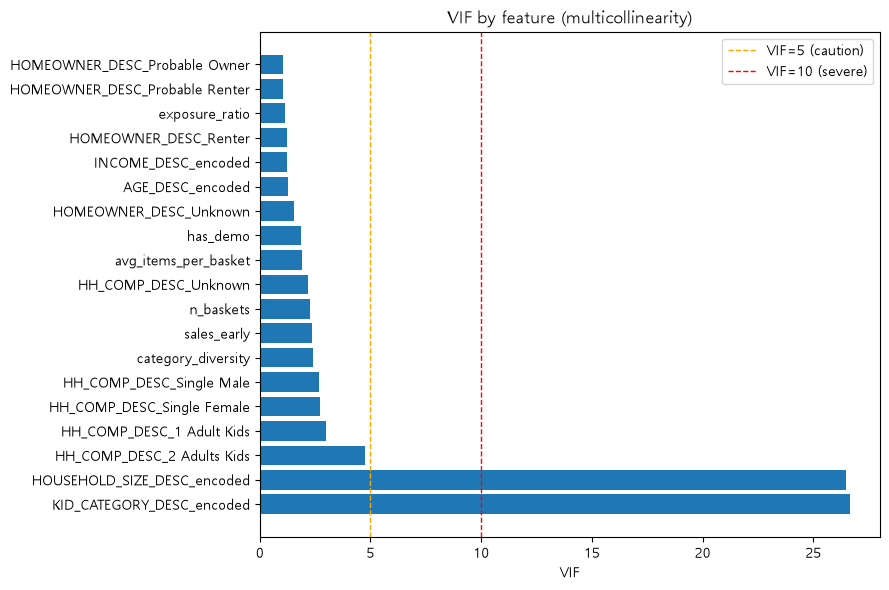

In [11]:
# Plot
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm


candidates = ["Malgun Gothic", "NanumGothic", "AppleGothic"]
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)
if font_name:
    plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(vif_data["feature"], vif_data["VIF"])
ax.axvline(5, color='orange', linestyle='--', linewidth=1, label='VIF=5 (caution)')
ax.axvline(10, color='red', linestyle='--', linewidth=1, label='VIF=10 (severe)')
ax.set_xlabel("VIF")
ax.set_title("VIF by feature (multicollinearity)")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
feature_cols_final = [c for c in feature_cols if c != "KID_CATEGORY_DESC_encoded"]

X_final = encoded_table[feature_cols_final]
X_final_const = add_constant(X_final)

vif_final = pd.DataFrame({
    "feature": X_final_const.columns,
    "VIF": [variance_inflation_factor(X_final_const.values, i) for i in range(X_final_const.shape[1])]
})
vif_final = vif_final[vif_final["feature"] != "const"].sort_values("VIF", ascending=False, kind="stable")
print(vif_final)

                           feature       VIF
9      HOUSEHOLD_SIZE_DESC_encoded  4.814787
15      HH_COMP_DESC_2 Adults Kids  4.019727
4               category_diversity  2.380506
1                      sales_early  2.370205
2                        n_baskets  2.275265
3             avg_items_per_basket  1.893916
6                         has_demo  1.841084
16      HH_COMP_DESC_Single Female  1.684571
14       HH_COMP_DESC_1 Adult Kids  1.602820
17        HH_COMP_DESC_Single Male  1.571883
13          HOMEOWNER_DESC_Unknown  1.515187
18            HH_COMP_DESC_Unknown  1.356165
7                 AGE_DESC_encoded  1.282913
8              INCOME_DESC_encoded  1.240645
12           HOMEOWNER_DESC_Renter  1.215890
5                   exposure_ratio  1.119114
10   HOMEOWNER_DESC_Probable Owner  1.060970
11  HOMEOWNER_DESC_Probable Renter  1.057826


In [13]:
# --- source CSVs: VIF before / after dropping KID_CATEGORY_DESC_encoded, and encoding summary
_v = vif_data.rename(columns={"VIF": "vif_before"}).merge(
    vif_final.rename(columns={"VIF": "vif_after"}), on="feature", how="left")
_v["dropped"] = _v["vif_after"].isna()
_v.to_csv(OUT_DIR / "ml_vif.csv", index=False)
pd.DataFrame([{
    "n_households": len(encoded_table), "n_has_demo": int(feature_table["has_demo"].sum()),
    "n_no_demo": int((feature_table["has_demo"] == 0).sum()),
    "n_features_before_vif": len(feature_cols), "n_features_final": len(feature_cols_final),
    "n_positive": int((encoded_table["label_shrink"] == 1).sum()),
    "epv_before_vif": (encoded_table["label_shrink"] == 1).sum() / len(feature_cols),
}]).to_csv(OUT_DIR / "ml_encoding_summary.csv", index=False)